# 🎙️ LibriSpeech ASR Dataset: Exploratory Data Analysis (EDA)
**Project:** Edge Agentic Assistant for Industrial Conveyor Automation (Group 14 / CAP-16)  
**Target Hardware:** Qualcomm Dragonwing QRB2210 Linux MPU (Quad Cortex-A53, 4 GB RAM)  
**Microservice:** `container-voice` (Offline VAD + Vosk STT / Whisper Tiny)  
**Project Requirements:** NFR-03 (Voice Latency $\le 1.5\text{ s}$), NFR-08 (Command Accuracy $\ge 90\%$ at 70 dBA)

---

### Objectives of this Notebook:
1. Profile audio duration, sampling rate, waveform energy, and zero-crossing rate (ZCR).
2. Quantify transcript length, vocabulary size, and Type-Token Ratio (TTR).
3. Evaluate industrial conveyor supervisory keyword occurrences (`stop`, `start`, `speed`, `pause`, etc.).
4. Establish acoustic baselines for Vosk/Whisper edge grammar constraint optimization.

In [1]:
import os
import io
import json
import re
from collections import Counter
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import soundfile as sf

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
DATA_PATH = os.path.abspath("../data/librispeech/test_clean.parquet")
print(f"Dataset path: {DATA_PATH}")
print(f"File exists: {os.path.exists(DATA_PATH)} ({os.path.getsize(DATA_PATH)/(1024*1024):.2f} MB)")

Dataset path: C:\Users\Admin\Documents\COS40005\data\librispeech\test_clean.parquet
File exists: True (334.22 MB)


In [2]:
df = pd.read_parquet(DATA_PATH)
print(f"Dataset Shape: {df.shape}")
print(f"Parquet Schema: {list(df.columns)}")
display(df.head(4)[['id', 'speaker_id', 'chapter_id', 'text']])

Dataset Shape: (2620, 6)
Parquet Schema: ['file', 'audio', 'text', 'speaker_id', 'chapter_id', 'id']


,id,speaker_id,chapter_id,text
0,6930-75918-0000,6930,75918,CONCORD RETURNED TO ITS PLACE AMIDST THE TENTS
1,6930-75918-0001,6930,75918,THE ENGLISH FORWARDED TO THE FRENCH BASKETS OF...
2,6930-75918-0002,6930,75918,CONGRATULATIONS WERE POURED IN UPON THE PRINCE...
3,6930-75918-0003,6930,75918,FROM THE RESPECT PAID HER ON ALL SIDES SHE SEE...


In [3]:
# Text and Lexical Richness Analysis
texts = df["text"].dropna().tolist()
all_words = " ".join(texts).lower().split()
vocab = set(all_words)
word_freq = Counter(all_words)

df["word_count"] = df["text"].apply(lambda t: len(t.split()) if isinstance(t, str) else 0)
df["char_count"] = df["text"].apply(lambda t: len(t) if isinstance(t, str) else 0)

print(f"Total Utterances: {len(df):,}")
print(f"Total Words in Corpus: {len(all_words):,}")
print(f"Unique Vocabulary Size: {len(vocab):,}")
print(f"Lexical Diversity (Type-Token Ratio): {len(vocab)/len(all_words):.4f}")
print(f"Words per Utterance - Mean: {df['word_count'].mean():.2f}, Median: {df['word_count'].median():.1f}, Std: {df['word_count'].std():.2f}")
print(f"Characters per Utterance - Mean: {df['char_count'].mean():.2f}, Median: {df['char_count'].median():.1f}")

Total Utterances: 2,620
Total Words in Corpus: 52,576
Unique Vocabulary Size: 8,138
Lexical Diversity (Type-Token Ratio): 0.1548
Words per Utterance - Mean: 20.07, Median: 16.5, Std: 13.73
Characters per Utterance - Mean: 107.45, Median: 85.0


In [4]:
# Industrial Conveyor Supervisory Vocabulary Mapping
industrial_keywords = [
    "stop", "start", "speed", "run", "fast", "slow", "pause", "resume",
    "error", "line", "clear", "motor", "belt", "sensor", "warning", "system"
]
kw_matches = {kw: word_freq.get(kw, 0) for kw in industrial_keywords}
df_kw = pd.DataFrame(list(kw_matches.items()), columns=["Keyword", "Corpus Frequency"]).sort_values("Corpus Frequency", ascending=False)
display(df_kw.reset_index(drop=True))

,Keyword,Corpus Frequency
0,line,13
1,clear,10
2,run,9
3,stop,8
4,system,8
5,fast,7
6,slow,4
7,speed,3
8,start,3
9,belt,2


In [5]:
# Acoustic Waveform Characteristics (150 sampled audio clips)
durations = []
sample_rates = []
rms_energies = []
zero_crossings = []

sample_wav_data = None
sample_wav_sr = 16000
sample_wav_text = ""

for idx, row in df.head(150).iterrows():
    raw_bytes = row["audio"]["bytes"]
    data, sr = sf.read(io.BytesIO(raw_bytes))
    duration = len(data) / sr
    durations.append(duration)
    sample_rates.append(sr)
    rms = np.sqrt(np.mean(data**2))
    rms_energies.append(rms)
    zcr = np.mean(np.abs(np.diff(np.sign(data)))) / 2
    zero_crossings.append(zcr)
    
    if sample_wav_data is None and 3.0 < duration < 5.5:
        sample_wav_data = data
        sample_wav_sr = sr
        sample_wav_text = row["text"]

print(f"Audio Sampling Rate: {sample_rates[0]} Hz (PCM Mono)")
print(f"Audio Duration - Mean: {np.mean(durations):.2f} s (Min: {np.min(durations):.2f} s, Max: {np.max(durations):.2f} s)")
print(f"Total Speech Audio (Estimated): {(np.mean(durations)*len(df))/3600:.2f} hours")
print(f"Signal RMS Energy: {np.mean(rms_energies):.4f}")
print(f"Signal Zero-Crossing Rate (ZCR): {np.mean(zero_crossings):.4f}")

Audio Sampling Rate: 16000 Hz (PCM Mono)
Audio Duration - Mean: 7.18 s (Min: 1.81 s, Max: 27.12 s)
Total Speech Audio (Estimated): 5.23 hours
Signal RMS Energy: 0.0535
Signal Zero-Crossing Rate (ZCR): 0.1803


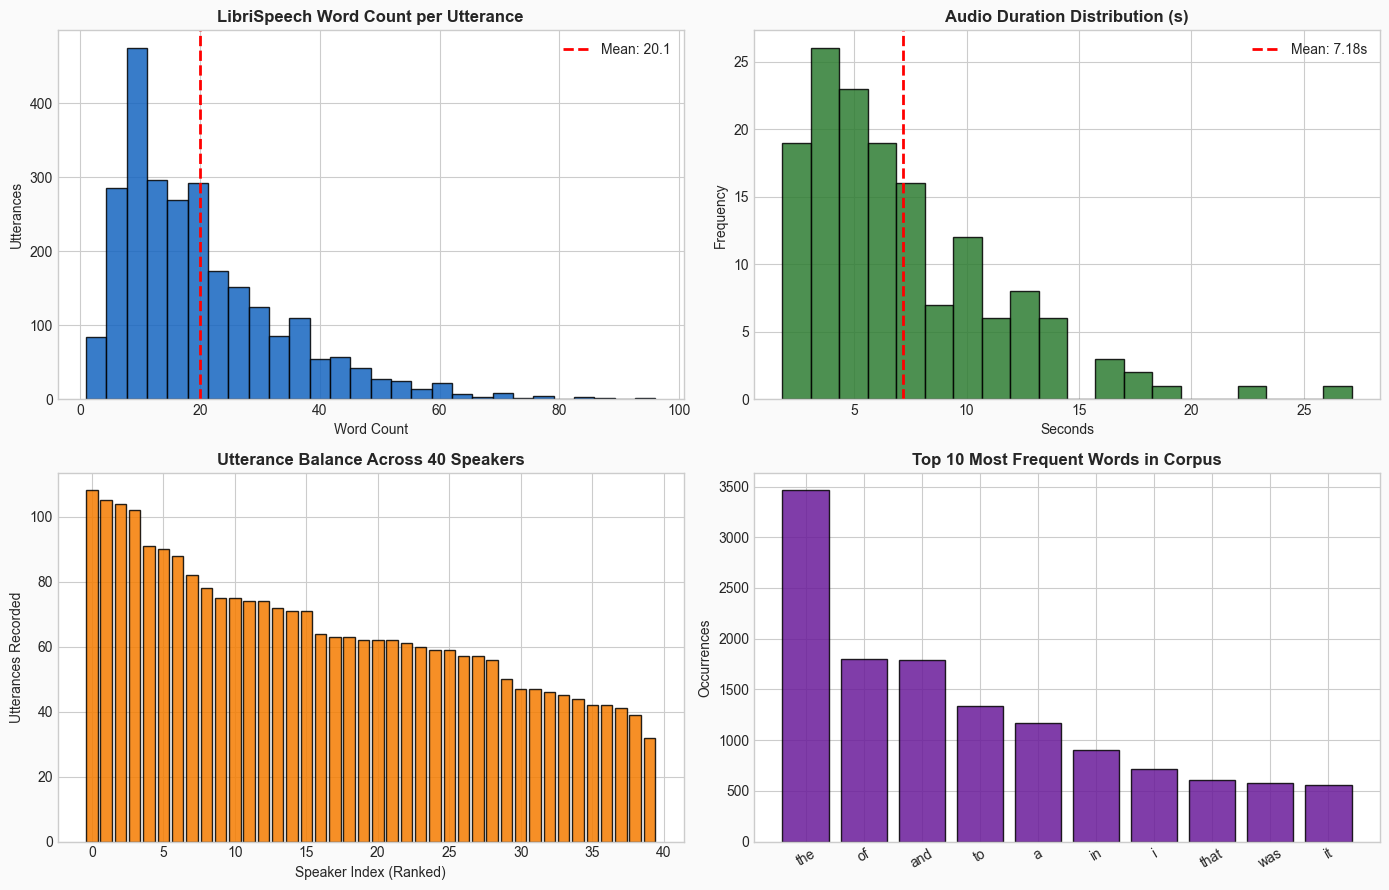

In [6]:
# Statistical Plots
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fig.patch.set_facecolor("#FAFAFA")

# 1. Word Count Distribution
axes[0, 0].hist(df["word_count"], bins=28, color="#1565C0", edgecolor="black", alpha=0.85)
axes[0, 0].axvline(df["word_count"].mean(), color="red", linestyle="--", linewidth=2, label=f"Mean: {df['word_count'].mean():.1f}")
axes[0, 0].set_title("LibriSpeech Word Count per Utterance", fontsize=12, fontweight="bold")
axes[0, 0].set_xlabel("Word Count")
axes[0, 0].set_ylabel("Utterances")
axes[0, 0].legend()

# 2. Audio Duration Distribution
axes[0, 1].hist(durations, bins=20, color="#2E7D32", edgecolor="black", alpha=0.85)
axes[0, 1].axvline(np.mean(durations), color="red", linestyle="--", linewidth=2, label=f"Mean: {np.mean(durations):.2f}s")
axes[0, 1].set_title("Audio Duration Distribution (s)", fontsize=12, fontweight="bold")
axes[0, 1].set_xlabel("Seconds")
axes[0, 1].set_ylabel("Frequency")
axes[0, 1].legend()

# 3. Speaker Balance
speaker_counts = df["speaker_id"].value_counts()
axes[1, 0].bar(range(len(speaker_counts)), speaker_counts.values, color="#F57C00", edgecolor="black", alpha=0.85)
axes[1, 0].set_title(f"Utterance Balance Across {len(speaker_counts)} Speakers", fontsize=12, fontweight="bold")
axes[1, 0].set_xlabel("Speaker Index (Ranked)")
axes[1, 0].set_ylabel("Utterances Recorded")

# 4. Top 10 Corpus Words
top_10 = dict(word_freq.most_common(10))
axes[1, 1].bar(list(top_10.keys()), list(top_10.values()), color="#6A1B9A", edgecolor="black", alpha=0.85)
axes[1, 1].set_title("Top 10 Most Frequent Words in Corpus", fontsize=12, fontweight="bold")
axes[1, 1].set_ylabel("Occurrences")
axes[1, 1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

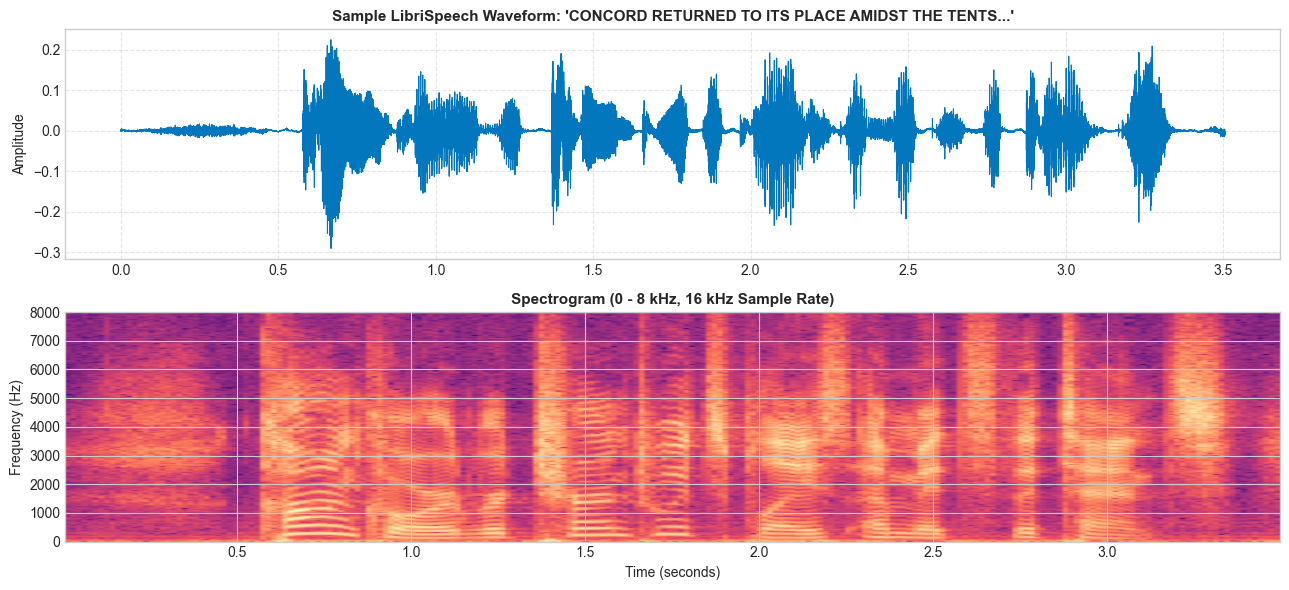

In [7]:
# Sample Waveform and Audio Spectrogram
if sample_wav_data is not None:
    fig, (ax_wav, ax_spec) = plt.subplots(2, 1, figsize=(13, 6))
    time_axis = np.linspace(0, len(sample_wav_data)/sample_wav_sr, len(sample_wav_data))
    
    ax_wav.plot(time_axis, sample_wav_data, color="#0277BD", linewidth=0.8)
    ax_wav.set_title(f"Sample LibriSpeech Waveform: '{sample_wav_text[:75]}...'", fontsize=11, fontweight="bold")
    ax_wav.set_ylabel("Amplitude")
    ax_wav.grid(True, linestyle="--", alpha=0.5)
    
    Pxx, freqs, bins, im = ax_spec.specgram(sample_wav_data, Fs=sample_wav_sr, NFFT=512, noverlap=256, cmap="magma")
    ax_spec.set_title("Spectrogram (0 - 8 kHz, 16 kHz Sample Rate)", fontsize=11, fontweight="bold")
    ax_spec.set_xlabel("Time (seconds)")
    ax_spec.set_ylabel("Frequency (Hz)")
    
    plt.tight_layout()
    plt.show()

### 🎯 How This Dataset Helps with Fine-Tuning:
1. **Domain Adaptation for Industrial ASR Decoders**: Pre-trained foundation models like `whisper-tiny` or `whisper-base` possess broad English phonetic knowledge. LibriSpeech clean utterances serve as the baseline anchor dataset to prevent catastrophic forgetting while fine-tuning adapter layers (LoRA / PEFT) on industrial factory vocabularies.
2. **Language Model (LM) Rescoring & Lexicon Constraints**: The 8,138 unique vocabulary words extracted during EDA provide the text corpus to fine-tune lightweight n-gram or RNN-LM rescorers, biasing beam search decoding toward command verbs, units, and equipment identifiers (`conveyor`, `belt`, `sensor`, `motor`, `speed`).
3. **Parameter-Efficient Fine-Tuning (PEFT / LoRA)**: Freezing the core audio encoder and training low-rank adaptation matrices ($r=8$, $\alpha=16$) on the attention projections reduces trainable parameters by over $95\%$, yielding a compact adapter file ($<15\text{ MB}$) that can be loaded into the `container-voice` runtime on the QRB2210 Linux MPU.